---
title: "FireIgnition: building the AI ready cube with DEFAIR"
subtitle: "A Destination Earth / DEFAIR use case: from six lightning, fuel, rain, air, fire and land cover products to one cube on a 10 km grid over the Iberian Peninsula"
author: "Author: Alejandro Fonseca (EUMETSAT/Starion)"
tags: [DEFAIR, HDA, MTG, LI LFL, FCI GII, LSA SAF, H SAF, CLC+, data cube]
thumbnail: ../img/EUMETSAT-icon.png
license: MIT
copyright: "© 2026 EUMETSAT"
---

<div style="margin: 6px 0;">
  <a href="https://jupyter.central.data.destination-earth.eu/user-redirect/lab/tree/DestinE-DataLake-Lab/DEFAIR/notebooks_support/DEDL_DEFAIR_Fire_ignition_cube_preparation.ipynb" target="_blank" style="text-decoration: none;">
    <span class="launch">🚀 Launch in JupyterHub</span>
  </a>
</div>

# Overview

This notebook builds the data cube used by
[DEDL_DEFAIR_Custom readers, lightning and fire](../DEDL_DEFAIR_Custom_readers_lightning_and_fire.ipynb). It reads six
products from the project bucket, puts them on one 10 km grid over the Iberian Peninsula, adds a fire label and
saves the result. The finished cube is published in the project bucket at

`s3://defair-use-case/cubes/fireignition_cube.zarr`

and the analysis notebook opens it directly from there. Run this notebook to see how the cube is made, to
change a design choice, or to build it again for another season.

```
one map per storm day, 37 of them
┌───┬───┬───┬───┬───┬───┐
│ · │ · │ L │ L │ · │ · │        ·    wildland cell
├───┼───┼───┼───┼───┼───┤
│ · │ L │[L]│ · │ · │ · │        L    lightning in the cell
├───┼───┼───┼───┼───┼───┤
│ · │ · │ · │ L │ L │ · │       [L]   lightning, then a new fire
├───┼───┼───┼───┼───┼───┤
│ · │ · │ · │ · │[·]│ · │       [·]   new fire without lightning
└───┴───┴───┴───┴───┴───┘
```

One sample is one 10 km cell on one storm day. For each cell and day the cube says whether lightning hit the
cell, describes the fuel, the rain and the air before the storm, and says whether a new fire appeared
afterwards. Only cells covered mostly by natural vegetation (wildland) enter the study. The three readers used
here, `lsa_frm`, `lsa509_frp` and `hsaf_h61`, are explained in the analysis notebook.

## Steps

1. Study grid and wildland mask
2. Lightning: flashes on the grid
3. Fuel, rain and air: three grids aligned with DEFAIR
4. The fire label
5. One storm day, built live
6. All storm days and the final sample
7. Saving the cube and checking the published one

## What the cube contains

Dimensions: `episode` (37 storm days), `y` (100 rows) and `x` (130 columns) of 10 km cells in EPSG:3035.

| Group | Variables | Product |
|---|---|---|
| Land cover | `wildland_fraction`, `lc_needleleaved`, `lc_broadleaved_deciduous`, `lc_broadleaved_evergreen`, `lc_low_woody`, `lc_permanent_herbaceous`, `lc_trees`, `eligible` | CLC+ Backbone 2023 |
| Lightning | `exposed`, `lfl_flash_count`, `lfl_duration_mean`, `lfl_footprint_mean`, `lfl_events_per_flash`, `lfl_first` | MTG LI LFL |
| Fuel | `frm_fwi`, `frm_ffmc`, `frm_dmc`, `frm_dc` | LSA SAF Fire Risk Map |
| Rain | `h61_precip` | H SAF H61B |
| Air before the storm | `gii_k_index`, `gii_lifted_index`, `gii_prec_water_total` | MTG FCI GII |
| Fire label | `fire_new`, `fire_first`, `frp_sum`, `frp_max`, `frp_24h`, `n_det`, `label_start`, `obs_fraction`, `burning_before` | LSA-509 FRP-Pixel |
| Sample | `fire_repeated`, `in_sample`, and the coordinates `onset` (the storm time) and `prior_complete` | all |

## Running it

Reading is anonymous, and by default the notebook runs in about two minutes. Steps 1 to 5 build the demo storm
day live from the raw products. Step 6 then reads all 37 storm days from the published cube; the demo day built
in step 5 is not added to it.

To build all 37 storm days yourself, set `BUILD_ALL = True` (about half an hour). Each finished day is saved to
disk, so the run can be stopped and resumed. The cube is saved in `data/fireignition/` next to this notebook and
compared with the published one. The notebook only reads from the bucket, so the published cube cannot be
changed from here.

## Prerequisites

The readers package is one folder up, in `../readers`. The cell below installs it. Restart the kernel after it
runs, so that DEFAIR can find the readers.

In [ ]:
%pip install -e ../readers matplotlib

In [18]:
from defair.logging import setup_logging
from defair.plugin_manager import load_source
from defair_data.core import Dataset
from defair_ops.transformations.alignment import AlignmentPlugin
from defair_ops.transformations.reprojection import ReferenceGrid

import time
from functools import lru_cache
from pathlib import Path

import boto3
from botocore import UNSIGNED
from botocore.client import Config
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from affine import Affine
from pyproj import CRS, Geod, Transformer

import warnings
warnings.filterwarnings("ignore", message="Consolidated metadata is currently not part")   # harmless Zarr 3 notice

setup_logging(log_level="ERROR")   # keeps the output readable; use "INFO" to inspect the pipeline

In [19]:
# Use case configuration

# Convective episodes of the 2026 season: days with at least 100 flashes over Iberia, found by a scan of the
# whole season of lightning data
EPISODES = ["2026-07-14", "2026-07-15", "2026-07-16", "2026-07-17", "2026-07-19",
            "2026-07-20", "2026-07-24", "2026-07-25", "2026-07-30", "2026-08-01", "2026-08-03",
            "2026-08-04", "2026-08-06", "2026-08-07", "2026-08-08", "2026-08-09", "2026-08-10",
            "2026-08-11", "2026-08-12", "2026-08-13", "2026-08-14", "2026-08-15", "2026-08-16",
            "2026-08-17", "2026-08-19", "2026-08-20", "2026-08-22", "2026-08-23", "2026-08-24",
            "2026-08-26", "2026-08-27", "2026-08-31", "2026-09-01", "2026-09-02", "2026-09-05",
            "2026-09-06", "2026-09-09"]
DEMO_EPISODE = "2026-08-10"                           # the storm day built live in step 5

# Study area and grid: EPSG:3035 at 10 km
BBOX = [-10.0, 36.0, 4.0, 44.0]                       # lon_min, lat_min, lon_max, lat_max
MARGIN = 2.0                                          # degrees kept around the bbox when cropping
X0, Y1, CELL, NX, NY = 2_600_000, 2_500_000, 10_000, 130, 100
X = X0 + CELL * (np.arange(NX) + 0.5)                 # cell centres
Y = Y1 - CELL * (np.arange(NY) + 0.5)
FACTOR = 10                                           # gridded sources are aligned at 1 km, then averaged 10 x 10
GRID_1KM = ReferenceGrid(crs="EPSG:3035", transform=Affine(CELL / FACTOR, 0.0, X0, 0.0, -CELL / FACTOR, Y1),
                         width=NX * FACTOR, height=NY * FACTOR)
SPATIAL_METHOD = "nearest"                            # the average over each 10 km cell is taken after alignment

# Lightning geolocation: every flash is moved from the ground to a cloud at a fixed height
SAT_LON, SAT_HEIGHT = 0.0, 35_786_400.0               # MTG-I1 sub satellite longitude [deg] and height [m]
PARALLAX_HEIGHT = 10_000.0                            # assumed height of the lightning [m]

# Decisions of the study design
WILDLAND_MIN_FRACTION = 0.5                           # at least 50 of the 100 km2 are natural vegetation
LABEL_HOURS, PRIOR_HOURS = 48, 48                     # label: 48 h from the first flash (or the storm time); prior: 48 h before
SLOTS_PER_WINDOW = LABEL_HOURS * 6                    # 10 minute slots in a label window
MIN_OBS_FRACTION = 0.25                               # a cell enters the sample when visible in a quarter of its window
GII_FROM, GII_TO = pd.Timedelta(hours=3), pd.Timedelta(hours=1)   # GII read from 3 h to 1 h before the storm time
PERSISTENT_GAP_DAYS, PERSISTENT_MIN_PERIODS = 7, 3    # a pixel active in 3 periods separated by 7 days is a fixed source
DAILY_SOURCE_MIN_DAYS = 20                            # a pixel active on 20 days of the season is a fixed source too
OBSERVED_CLASSES = [0, 1, 2]                          # quality flags where fire detection was possible

# Build all storm days or only the demo day; where the local cube is saved and the published cube is read
BUILD_ALL = False                                     # True builds the 37 storm days (about 30 min); False reads them
CUBE_DIR = Path.cwd() / "data" / "fireignition"
LOCAL_CUBE = CUBE_DIR / "fireignition_cube.zarr"
CUBE_KEY = "cubes/fireignition_cube.zarr/"

In [20]:
# S3 access

#=====================================================================================
# S3 object store: edit these three lines to point at a different store
S3_ENDPOINT = "https://s3.central.data.destination-earth.eu"
BUCKET      = "defair-use-case"
PREFIX      = ""   # source prefixes and cubes/ live at the bucket root
#=====================================================================================

# The bucket is public for reading, so every read is anonymous
S3_SOURCE_KWARGS = {"anon": True, "endpoint_url": S3_ENDPOINT}
READ = {"source": "s3", "source_kwargs": S3_SOURCE_KWARGS}
STORAGE_OPTIONS = {"anon": True, "client_kwargs": {"endpoint_url": S3_ENDPOINT}}

s3 = boto3.client("s3", endpoint_url=S3_ENDPOINT, config=Config(signature_version=UNSIGNED))
paginator = s3.get_paginator("list_objects_v2")   # the bucket holds more than 1000 objects

def s3_keys(prefix):
    """All object keys under a prefix."""
    return sorted(o["Key"] for p in paginator.paginate(Bucket=BUCKET, Prefix=PREFIX + prefix)
                  for o in p.get("Contents", []))

# Where each raw product of one day sits in the bucket
def frm_path(day):
    d = pd.Timestamp(day)
    return f"s3://{BUCKET}/{PREFIX}frm-orig/{d:%Y-%m-%d}/S-LSA_-HDF5_LSASAF_MSG_FRM-F024_Euro_{d:%Y%m%d}1200"

def h61_path(day):
    sealed = pd.Timestamp(day) + pd.Timedelta(days=1)      # the accumulation of day D is sealed at D+1 00:00
    return f"s3://{BUCKET}/{PREFIX}precip-orig/h61_{sealed:%Y%m%d}_0000_24_fdk.nc.gz"

def lsa_path(day):
    return f"s3://{BUCKET}/{PREFIX}lsa509-iberia/LSA509_iberia_{pd.Timestamp(day):%Y%m%d}.nc"

# Step 1: study grid and wildland mask

Every source of the cube ends on the same grid: EPSG:3035, the equal area projection of the European
Environment Agency, with cells of 10 km (100 km²), 130 columns by 100 rows. In an equal area grid every cell has
the same surface, which matters because flashes and fires are counted per cell. The grid is fixed in advance,
so every run produces exactly the same cells.

The land cover was brought to this grid when it was copied to the bucket: for every cell, the file holds the
number of 10 m CLC+ pixels of each class. Dividing by the million pixels of a full cell gives the fraction of the
cell covered by each class.

A cell enters the study when two conditions hold. At least half of it is natural vegetation, which keeps the
cells dominated by forest, shrubs and grassland and leaves out those dominated by crops, where many fires are
agricultural burns that would look like ignitions. And its centre lies inside the study area, because the
rectangular grid reaches beyond it at the corners, where the land cover was not downloaded.

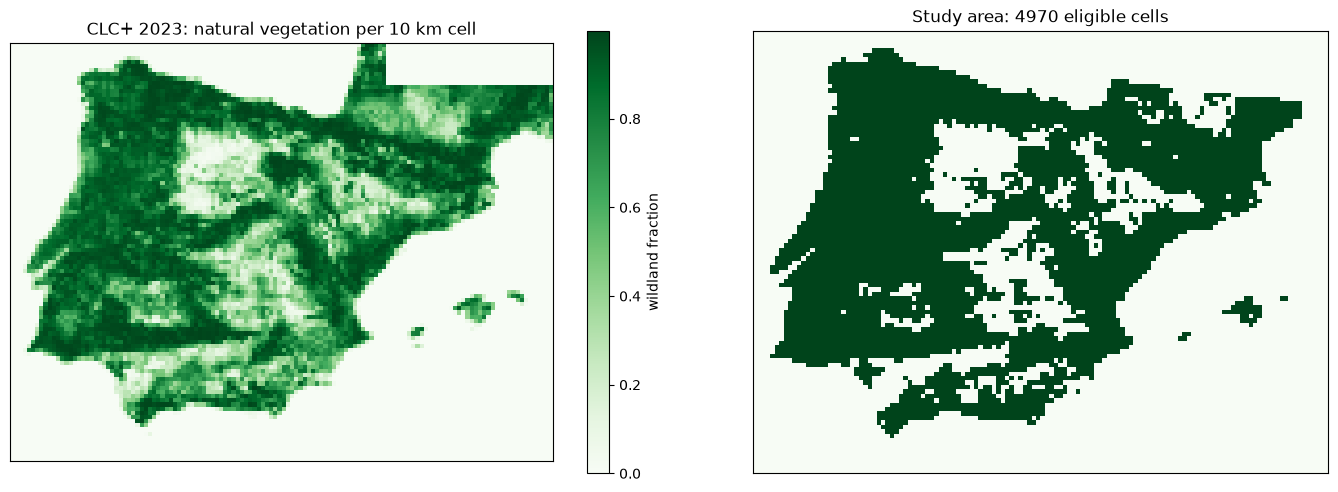

In [21]:
# The aggregated land cover: how many 10 m CLC+ pixels of each class fall in every 10 km cell
with load_source("s3", **S3_SOURCE_KWARGS).open(f"s3://{BUCKET}/{PREFIX}aux/landcover_10km_2023.npz") as f:
    lc = dict(np.load(f))

# The fraction of the cell covered by each class
fraction = lc["counts"] / (CELL / 10) ** 2
classes = {2: "needleleaved", 3: "broadleaved_deciduous", 4: "broadleaved_evergreen",
           5: "low_woody", 6: "permanent_herbaceous"}
static = xr.Dataset({f"lc_{name}": (("y", "x"), fraction[list(lc["classes"]).index(c)])
                     for c, name in classes.items()}, coords={"x": X, "y": Y})
static["wildland_fraction"] = sum(static[v] for v in list(static.data_vars))
static["lc_trees"] = static.lc_needleleaved + static.lc_broadleaved_deciduous + static.lc_broadleaved_evergreen

# The study area: enough natural vegetation, and the centre of the cell inside the bounding box
cx, cy = np.meshgrid(X, Y)
clon, clat = Transformer.from_crs("EPSG:3035", "EPSG:4326", always_xy=True).transform(cx, cy)
in_bbox = (clon >= BBOX[0]) & (clon <= BBOX[2]) & (clat >= BBOX[1]) & (clat <= BBOX[3])
static["eligible"] = (("y", "x"), in_bbox & (static.wildland_fraction.values >= WILDLAND_MIN_FRACTION))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
static.wildland_fraction.plot(ax=axes[0], cmap="Greens", cbar_kwargs={"label": "wildland fraction"})
static.eligible.plot(ax=axes[1], cmap="Greens", add_colorbar=False)
axes[0].set_title("CLC+ 2023: natural vegetation per 10 km cell")
axes[1].set_title(f"Study area: {int(static.eligible.sum())} eligible cells")
for ax in axes:
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()

Flashes and fire detections are points, not grids. Three small functions place them on the grid: `to_cell`
finds the cell of each position, `to_grid` writes one value per cell into a map, and `to_seconds` turns times
into numbers that fit in a map.

In [22]:
to_laea = Transformer.from_crs("EPSG:4326", "EPSG:3035", always_xy=True)

def to_cell(lon, lat):
    """Index of the 10 km cell containing each position (row * NX + col), -1 outside the grid."""
    fx, fy = to_laea.transform(lon, lat)
    col = np.floor((fx - X0) / CELL).astype(int)
    row = np.floor((Y1 - fy) / CELL).astype(int)
    return np.where((col >= 0) & (col < NX) & (row >= 0) & (row < NY), row * NX + col, -1)

def to_grid(cells, values, fill=np.nan):
    """A (y, x) map holding the values in the given cells and fill everywhere else."""
    grid = np.full(NY * NX, fill)
    grid[cells] = values
    return grid.reshape(NY, NX)

def to_seconds(t):
    """Seconds since 1970 of a time or a series of times, whatever their unit."""
    return (pd.to_datetime(t) - pd.Timestamp("1970-01-01")) / pd.Timedelta(seconds=1)

# Step 2: lightning

The flash product (LI LFL) has one file every 10 minutes, 144 a day, and each file is a list of flashes. The
files of a day are read one by one with the built-in reader `mtg_li_lfl` and joined into one table.

The Lightning Imager places each flash where its line of sight meets the ground. Lightning happens inside the
cloud, several kilometres up, so over Iberia each flash is recorded about 10 km north of where it was, the size
of one cell. The correction moves each flash back along the line of sight to an assumed cloud height of 10 km.
Real flash heights vary, so a small error remains.

<img src="img/parallax.png" width="420" alt="Parallax correction of a flash">

The corrected flashes of the day are then counted into the cells. Four things come out of them:

```
exposure      did the cell get at least one flash?
storm         number of flashes, and their mean duration, size and number of light pulses
first flash   when the first flash fell in the cell: the start of its label window (step 4)
storm time    the median time of the first flash over the wildland cells with lightning (`onset` in the
              code and in the cube). Each cell counts once, so a few flashes at night do not move it. It
              starts the window of the cells without lightning and sets when the air is read (step 3)
```

In [23]:
# Lightning: the flashes of the episode day, corrected for parallax, counted and described in every cell
LFL_FIELDS = ["flash_time", "longitude", "latitude", "flash_duration", "flash_footprint", "number_of_events"]

# The Lightning Imager places each flash where its line of sight meets the ground. The flash is moved back
# along that line to the height of the cloud: over Iberia about 10 km to the south
A_WGS84, B_WGS84 = 6378137.0, 6356752.314245
TO_ECEF = Transformer.from_crs("EPSG:4979", "EPSG:4978", always_xy=True)
TO_GEODETIC = Transformer.from_crs("EPSG:4978", "EPSG:4979", always_xy=True)
SATELLITE = np.array(TO_ECEF.transform(SAT_LON, 0.0, SAT_HEIGHT))

def parallax_correct(lon, lat, height=PARALLAX_HEIGHT):
    """Position of each flash where the line of sight of the satellite crosses the given height."""
    ground = np.stack(TO_ECEF.transform(lon, lat, np.zeros_like(lon)), axis=-1)
    view = ground - SATELLITE
    w = np.array([1 / (A_WGS84 + height) ** 2, 1 / (A_WGS84 + height) ** 2, 1 / (B_WGS84 + height) ** 2])
    qa, qb, qc = (w * view ** 2).sum(-1), 2 * (w * SATELLITE * view).sum(-1), (w * SATELLITE ** 2).sum() - 1
    t = (-qb - np.sqrt(qb ** 2 - 4 * qa * qc)) / (2 * qa)        # first crossing of the shell at that height
    x, y, z = (SATELLITE + t[:, None] * view).T
    lon_c, lat_c, _ = TO_GEODETIC.transform(x, y, z)
    return lon_c, lat_c

# Check: a flash seen over the centre of Iberia moves about 10 km south, towards the point under the satellite
lon_c, lat_c = parallax_correct(np.array([-4.0]), np.array([40.0]))
azimuth, _, shift = Geod(ellps="WGS84").inv(-4.0, 40.0, lon_c[0], lat_c[0])
print(f"parallax correction at 4 W, 40 N: {shift / 1000:.1f} km towards azimuth {azimuth:.0f} deg")

def read_flashes(day):
    """All flashes of the episode day inside the study area, corrected for parallax, as a table."""
    # The 144 slots of the day are read one by one: the multifile concatenation degenerates on point products
    tables = []
    for key in s3_keys(f"lfl-orig/{day}/"):
        f = Dataset.from_source(f"s3://{BUCKET}/{key}", reader="mtg_li_lfl", **READ).data
        tables.append(pd.DataFrame({v: np.ravel(f[v].values) for v in LFL_FIELDS}))
    fl = pd.concat(tables, ignore_index=True)
    # One slot starts before midnight, so the flashes are cut to the calendar day
    d = pd.Timestamp(day)
    fl = fl[fl.flash_time.between(d, d + pd.Timedelta(days=1), inclusive="left")].copy()
    fl["longitude"], fl["latitude"] = parallax_correct(fl.longitude.values.astype(float), fl.latitude.values.astype(float))
    return fl[fl.longitude.between(BBOX[0], BBOX[2]) & fl.latitude.between(BBOX[1], BBOX[3])]

def lightning_features(fl):
    """Storm descriptors of every cell: count, duration, footprint, events per flash and first flash."""
    g = fl.assign(cell=to_cell(fl.longitude.values, fl.latitude.values)).query("cell >= 0").groupby("cell")
    stats = pd.DataFrame({"lfl_flash_count": g.size(),
                          "lfl_duration_mean": g.flash_duration.mean(),
                          "lfl_footprint_mean": g.flash_footprint.mean(),
                          "lfl_events_per_flash": g.number_of_events.mean(),
                          "lfl_first": to_seconds(g.flash_time.min())})
    # A cell without flashes counts zero of them, but has no duration, footprint or first flash
    return {name: to_grid(values.index, values.values, 0.0 if name == "lfl_flash_count" else np.nan)
            for name, values in stats.items()}

def storm_time(first_flash):
    """The storm time of the day: the median first flash over the wildland cells with lightning."""
    first = first_flash[static.eligible.values & np.isfinite(first_flash)]
    return pd.to_datetime(np.median(first), unit="s")

parallax correction at 4 W, 40 N: 10.5 km towards azimuth 174 deg


# Step 3: fuel, rain and air

The air before the storm comes from the GII, which says how much water the air held and how unstable it was.
This helps tell apart storms that bring rain with their lightning from dry ones. The satellite can only measure
the GII under clear sky, and during the storm the cells with lightning are under thick cloud, so the air is read
before the storm:

```
          storm time - 3 h            storm time - 1 h       storm time
   ────────────|────────────────────────────|────────────────────|────▶ time
               └──── GII read every 10 min ─┘   left out:        storm
                     last clear value kept      clouds already   begins
                     for each pixel             building up
```

The storm time is one time for the whole study area, so for a cell that the storm reaches late in the day the
GII describes the air of the morning. Each GII file lacks coordinates for a slightly different set of pixels,
so the coordinates of all the files are combined first. The result is then cropped once, to the study area plus
a margin of 2°.

The Fire Risk Map (fuel), H61B (rain) and the GII (air) each give one map per storm day, on three different
grids. Each is given the date of the storm day, because each product writes its date differently, and then one
DEFAIR alignment call puts all three on the study grid and merges them. DEFAIR adds the product name in front of
each variable, so variables are picked by the end of their name.

Over Iberia a 10 km cell holds about seven SEVIRI pixels of the Fire Risk Map and H61B, and about three FCI
pixels of the GII. Rain in particular can fall on only a few of them, so the pixel at the centre of the cell
may miss it. The fair value for the cell is the average of all its pixels. DEFAIR's resampling methods (nearest,
bilinear, cubic) estimate the value at the centre of the cell, so the average is built in two steps:

```
source pixels ──▶ 1 km grid   (nearest: each pixel copied onto the 1 km cells it covers)
              ──▶ 10 km grid  (average of each 10 x 10 block of 1 km cells)
```

Where part of a cell has no data, at the coast or in a gap of a source, the average uses only the 1 km cells
that have data.

In [24]:
# Atmosphere: the instability indices of the last clear sky before the storm
CROP = {"lat_min": BBOX[1] - MARGIN, "lat_max": BBOX[3] + MARGIN,
        "lon_min": BBOX[0] - MARGIN, "lon_max": BBOX[2] + MARGIN}
GII_VARS = ["k_index", "lifted_index", "prec_water_total"]

def gii_before_onset(day, onset):
    """Last clear GII value per pixel between 3 h and 1 h before the onset, as a DEFAIR Dataset."""
    d = pd.Timestamp(day)
    slots = pd.date_range((onset - GII_FROM).floor("10min"), (onset - GII_TO).floor("10min"), freq="10min")
    last_clear = lat = lon = None
    # Slot after slot, every pixel keeps the most recent value it had under clear sky
    for s in slots[slots >= d]:
        cycle = f"{(s - d) // pd.Timedelta(minutes=10) + 1:04d}"
        try:
            gii_ds = Dataset.from_source(f"s3://{BUCKET}/{PREFIX}gii-orig/{d:%Y%m%d}/*_{cycle}_????.nc",
                                         reader="mtg_l2_gii", **READ)
        except FileNotFoundError:
            continue                                        # slot missing from the archive
        g = gii_ds.transform("content_filter", include_vars=GII_VARS).data.isel(time=0, drop=True)
        lat = g.lat if lat is None else lat.fillna(g.lat)   # each file leaves a different set of pixels without position
        lon = g.lon if lon is None else lon.fillna(g.lon)
        g = g.drop_vars(["lat", "lon"])
        last_clear = g if last_clear is None else g.where(g.notnull(), last_clear)
    if last_clear is None:
        return None                                         # no GII slot available before the onset
    # The crop comes last, on the positions joined from every slot, so that all of them share one window
    inside_crop = ((lat >= CROP["lat_min"]) & (lat <= CROP["lat_max"]) &
                   (lon >= CROP["lon_min"]) & (lon <= CROP["lon_max"])).values
    rows, cols = np.flatnonzero(inside_crop.any(axis=1)), np.flatnonzero(inside_crop.any(axis=0))
    window = {"y": slice(rows[0], rows[-1] + 1), "x": slice(cols[0], cols[-1] + 1)}
    last_clear = last_clear.assign_coords(lat=lat, lon=lon).isel(window)
    return Dataset(last_clear.expand_dims(time=[d]))

In [25]:
# Fuel, rain and atmosphere: three grids brought onto one, and averaged into the 10 km cells
GRIDDED = {"frm_fwi": "FWI", "frm_ffmc": "FFMC", "frm_dmc": "DMC", "frm_dc": "DC",
           "h61_precip": "acc_rr",
           "gii_k_index": "k_index", "gii_lifted_index": "lifted_index", "gii_prec_water_total": "prec_water_total"}

def pick(ds_aligned, suffix):
    """The variable whose name ends with suffix, or NaN everywhere if the source was not available."""
    match = [v for v in ds_aligned.data_vars if v.endswith(suffix)]
    return ds_aligned[match[0]].values if match else np.full((NY, NX), np.nan)

def gridded_features(day, gii):
    """FRM, H61B and the pre storm GII of one episode, aligned at 1 km and averaged into the 10 km cells."""
    d = pd.Timestamp(day)
    # The three products describe the same episode but each writes its date differently
    stamp = lambda source: Dataset(source.data.assign_coords(time=[d]))
    frm = stamp(Dataset.from_source(frm_path(day), reader="lsa_frm", **READ))
    h61 = stamp(Dataset.from_source(h61_path(day), reader="hsaf_h61", **READ))
    # One call brings the three grids onto the fine grid; the 10 x 10 average then gives the cell mean
    with AlignmentPlugin() as plugin:
        fine = plugin.transform(frm, target=GRID_1KM, datasets=[h61] + ([gii] if gii else []),
                                spatial_method=SPATIAL_METHOD).data.isel(time=0, drop=True)
    aligned = fine.coarsen(x=FACTOR, y=FACTOR).mean().compute()
    assert np.allclose(aligned.x, X) and np.allclose(aligned.y, Y)
    return {name: pick(aligned, suffix) for name, suffix in GRIDDED.items()}

# Step 4: the fire label

The label says, for each cell and storm day, whether a new fire appeared after the storm. It comes from the
LSA-509 FRP-Pixel product, which lists every fire detection: one hot 1 km pixel in one 10 minute image.

Each cell has its own 48 hour window. In a cell with lightning it starts at the first flash; in a cell without
lightning it starts at the storm time of the day (step 2). A fire first seen inside the window is new.

```
                                  first flash in the cell
with lightning     ├────── 48 h before ───────┼─────── 48 h after ───────┤
                         no fire nearby                new fire?

                                   storm time of the day
without lightning  ├────── 48 h before ───────┼─────── 48 h after ───────┤
                         no fire nearby                new fire?
```

Three checks make sure a detection is a new wildfire. The first removes detections; the other two mark cells
that leave the sample in step 6.

- Not a fixed source. A wildfire burns for hours or days and stops when the fuel is gone; a gas flare or a
  steelworks stays hot all season. For every 1 km pixel, the days with detections are grouped into periods,
  and a new period starts after a week without any. A pixel with three or more periods, or with detections on
  twenty or more days, is a fixed source and is removed together with its eight neighbours. The rule works pixel
  by pixel, so a real fire that shares a cell with a factory is kept.
- Not already burning. If the cell or one of its eight neighbours had a fire in the 48 hours before the window,
  a later detection is probably the same fire, or one spreading in from next door. These cells are marked in
  `burning_before`.
- Seen by the satellite. Clouds hide fires, so no detection does not always mean no fire. The quality image of
  the product says, for every pixel and every image, whether a fire could have been detected (flags 0, 1 and 2).
  The visible share of each cell's window is stored in `obs_fraction`; cells visible in less than a quarter of
  their window are marked by it.

The cell below reads every detection of the season in one call and removes the fixed sources.

In [26]:
# Every detection of the season, read in one call
lsa_keys = s3_keys("lsa509-iberia/")
LSA_DAYS = {pd.Timestamp(k[-11:-3]) for k in lsa_keys}

fires = Dataset.from_source([f"s3://{BUCKET}/{k}" for k in lsa_keys], reader="lsa509_frp",
                            product="fires", concat_dim="fire", **READ).data
det = pd.DataFrame({"line": fires.ABS_LINE.values.astype(int), "samp": fires.ABS_SAMP.values.astype(int),
                    "time": pd.to_datetime(fires.ACQTIME.values), "frp": fires.FRP.values,
                    "lon": fires.LONGITUDE_PARALLAX.values, "lat": fires.LATITUDE_PARALLAX.values})

# For every FCI pixel, its days of activity are grouped into periods separated by a week without detections
days = det.assign(day=det.time.dt.normalize())[["line", "samp", "day"]].drop_duplicates().sort_values(["line", "samp", "day"])
gap = days.groupby(["line", "samp"]).day.diff().dt.days
days["period"] = (gap.isna() | (gap >= PERSISTENT_GAP_DAYS)).groupby([days.line, days.samp]).cumsum()
recurrence = days.groupby(["line", "samp"]).period.max()
active_days = days.groupby(["line", "samp"]).size()

# A fixed source comes back in three periods, or is active on too many days to be a wildfire:
# it and its eight neighbours are dropped
recurrent, daily = recurrence >= PERSISTENT_MIN_PERIODS, active_days >= DAILY_SOURCE_MIN_DAYS
fixed = recurrent | daily
sources = fixed[fixed].index.to_frame(index=False)
neighbourhood = pd.concat([sources + [dl, ds_] for dl in (-1, 0, 1) for ds_ in (-1, 0, 1)]).drop_duplicates()
keep = ~pd.MultiIndex.from_frame(det[["line", "samp"]]).isin(pd.MultiIndex.from_frame(neighbourhood))

print(f"{len(det)} detections on {len(LSA_DAYS)} days | {len(sources)} fixed source pixels "
      f"({int(recurrent.sum())} recurrent, {int(daily.sum())} active on {DAILY_SOURCE_MIN_DAYS} days or more) | "
      f"{int((~keep).sum())} detections removed")
det = det[keep].reset_index(drop=True)
det["cell"] = to_cell(det.lon.values, det.lat.values)   # the cell of every detection, computed once

171685 detections on 64 days | 83 fixed source pixels (76 recurrent, 9 active on 20 days or more) | 7143 detections removed


The quality image has one value per 1 km pixel and per 10 minute image. The visible share of a window is
computed in three moves:

1. Each pixel is placed in its 10 km cell, once for the whole season.
2. For each day of the archive, the visible pixels are counted per cell and per image.
3. A window can cover the storm day and the two days after it. Over those three days the counts are added up
   into a running total, so the visible pixels of any window are the total at its end minus the total at its
   start.

In [27]:
# Each pixel of the quality image is placed in its 10 km cell once, from the projection written by the reader
quality = Dataset.from_source(lsa_path(DEMO_EPISODE), reader="lsa509_frp", product="quality", **READ).data
geos = CRS.from_cf(quality["geostationary"].attrs)
qx, qy = np.meshgrid(quality.x.values, quality.y.values)
pixel_cell = to_cell(*Transformer.from_crs(geos, "EPSG:4326", always_xy=True).transform(qx, qy)).ravel()
inside = pixel_cell >= 0
cell_pixels = np.bincount(pixel_cell[inside], minlength=NX * NY)   # FCI pixels per cell

@lru_cache(maxsize=3)   # consecutive storm days share days, so the last three are kept in memory
def observed_slots(day):
    """Slot times of one day of the fire archive, and the observable pixels of every cell in each slot."""
    flags = Dataset.from_source(lsa_path(day), reader="lsa509_frp", product="quality", **READ).data.qualityflag
    observable = flags.isin(OBSERVED_CLASSES).values.reshape(flags.sizes["time"], -1)[:, inside]
    counts = np.stack([np.bincount(pixel_cell[inside], weights=slot, minlength=NX * NY) for slot in observable])
    return flags.time.values.astype("datetime64[ns]"), counts.astype(np.int32)

def observed_in_window(day, start, span):
    """Observable pixel slots of every cell between its own start time and start + span.
    A window starts on the storm day, so it ends within the storm day and the two days after it."""
    times, counts = zip(*(observed_slots(t) for t in pd.date_range(day, periods=3) if t in LSA_DAYS))
    times = np.concatenate(times)
    assert np.all(np.diff(times) > np.timedelta64(0, "ns")), "quality slots must increase in time"
    running = np.vstack([np.zeros((1, NX * NY), np.int32),
                         np.cumsum(np.concatenate(counts), axis=0, dtype=np.int32)])   # running total per cell
    first, last = np.searchsorted(times, start), np.searchsorted(times, start + span)
    cells = np.arange(NX * NY)
    return running[last, cells] - running[first, cells]

`burning_before` marks the cells where a fire was already burning: a detection in the cell or in one of its
eight neighbours in the 48 hours before the cell's window starts.

In [28]:
def burning_before(near, t0):
    """True where the cell or one of its eight neighbours had a detection in the 48 h before its start,
    so that a fire spreading in from next door is not taken for a new one."""
    when = near.time.values.astype("datetime64[ns]")
    prior = np.timedelta64(PRIOR_HOURS, "h")
    burning = np.zeros(NY * NX, bool)
    row, col = near.cell.values // NX, near.cell.values % NX
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            r, c = row + dr, col + dc
            ok = (r >= 0) & (r < NY) & (c >= 0) & (c < NX)
            target = r[ok] * NX + c[ok]
            hit = (when[ok] >= t0[target] - prior) & (when[ok] < t0[target])
            burning[target[hit]] = True
    return burning

`label_episode` labels one storm day with the pieces above. `fire_new` is 1 when the cell has a detection inside
its window, 0 when it has none but was visible at some point, and empty when it was never visible. For every new
fire the cube also keeps when it was first seen and its Fire Radiative Power, so it can also be used to study
how much energy the new fires release.

In [29]:
def label_episode(day, start):
    """Label, fire identity and energy, earlier fire and observability of every cell, from its start time."""
    d = pd.Timestamp(day)
    t0 = pd.to_datetime(start.ravel(), unit="s").values.astype("datetime64[ns]")
    span = np.timedelta64(LABEL_HOURS, "h")
    near = det[det.time.between(d - pd.Timedelta(hours=PRIOR_HOURS), d + pd.Timedelta(days=3), inclusive="left")
               & (det.cell >= 0)]
    when = near.time.values.astype("datetime64[ns]")

    # A fire is new in a cell when it is first seen inside the label window of that cell
    own_start = t0[near.cell.values]
    window = near[(when >= own_start) & (when < own_start + span)]
    by_cell = window.groupby("cell").agg(fire_first=("time", "min"), frp_sum=("frp", "sum"),
                                         frp_max=("frp", "max"), n_det=("frp", "size"))
    # The power of each fire summed over the 24 h after it was first seen: the same span for every fire
    follow = det.join(by_cell.fire_first.rename("first"), on="cell", how="inner")
    follow = follow[(follow.time >= follow["first"]) & (follow.time < follow["first"] + pd.Timedelta(hours=24))]
    by_cell["frp_24h"] = follow.groupby("cell").frp.sum()
    by_cell["fire_first"] = to_seconds(by_cell.fire_first)
    layers = {name: to_grid(values.index, values.values) for name, values in by_cell.items()}

    # Observability: the share of the pixel slots of the window in which a fire could have been seen
    observed = observed_in_window(d, t0, span)
    obs_fraction = np.full(NY * NX, np.nan)
    has_pixels = cell_pixels > 0
    obs_fraction[has_pixels] = observed[has_pixels] / (cell_pixels[has_pixels] * SLOTS_PER_WINDOW)

    fire = np.isin(np.arange(NY * NX), window.cell.values)
    return {
        "fire_new": np.where(fire, 1.0, np.where(observed > 0, 0.0, np.nan)).reshape(NY, NX),
        "burning_before": burning_before(near, t0).reshape(NY, NX),
        "obs_fraction": obs_fraction.reshape(NY, NX),
        "label_start": start,
        "prior_complete": all(t in LSA_DAYS for t in pd.date_range(d - pd.Timedelta(days=2), periods=2)),
        **layers,
    }

# Step 5: one storm day, built live

The builder puts the pieces together for one storm day. The flashes give the exposure, the storm description,
the first flash of every cell and the storm time. The storm time sets when the GII is read. The alignment brings
fuel, rain and air onto the grid. The label comes from the cleaned detections, inside the window of each cell.
Every piece ends as a (y, x) map, so a storm day is a plain xarray dataset with one extra dimension, `episode`,
of length one.

The cell below builds the demo storm day from the raw products, exactly as every day of the season is built.

In [30]:
def build_episode(day):
    """The cube of one episode: every source on the 10 km grid, one (y, x) layer per variable."""
    d = pd.Timestamp(day)
    fl = read_flashes(day)
    lightning = lightning_features(fl)
    onset = storm_time(lightning["lfl_first"])
    # The label window of every cell starts at its first flash, or at the storm time without one
    start = np.where(np.isnan(lightning["lfl_first"]), to_seconds(onset), lightning["lfl_first"])
    label = label_episode(day, start)
    prior_complete = label.pop("prior_complete")
    layers = gridded_features(day, gii_before_onset(day, onset)) | lightning | label
    ep = xr.Dataset({name: (("y", "x"), values) for name, values in layers.items()}, coords={"x": X, "y": Y})
    ep["exposed"] = ep.lfl_flash_count > 0
    return ep.expand_dims(episode=[d]).assign_coords(onset=("episode", [onset]),
                                                     prior_complete=("episode", [prior_complete]))

t0 = time.time()
demo = build_episode(DEMO_EPISODE)
print(f"{DEMO_EPISODE} built in {time.time() - t0:.0f} s | cells with lightning: {int(demo.exposed.sum())} | "
      f"new fires: {int((demo.fire_new == 1).sum())} | burning before: {int(demo.burning_before.sum())} | "
      f"median visible share: {float(demo.obs_fraction.median()):.2f} | onset: {pd.Timestamp(demo.onset.values[0]):%H:%M} UTC")
demo

2026-08-10 built in 52 s | cells with lightning: 1402 | new fires: 84 | burning before: 729 | median visible share: 0.52 | onset: 14:28 UTC


<xarray.Dataset> Size: 2MB
Dimensions:               (episode: 1, y: 100, x: 130)
Coordinates:
  * episode               (episode) datetime64[us] 8B 2026-08-10
    onset                 (episode) datetime64[ns] 8B 2026-08-10T14:28:56.556...
    prior_complete        (episode) bool 1B True
  * y                     (y) float64 800B 2.495e+06 2.485e+06 ... 1.505e+06
  * x                     (x) float64 1kB 2.605e+06 2.615e+06 ... 3.895e+06
Data variables: (12/23)
    frm_fwi               (episode, y, x) float32 52kB nan nan ... 63.67 55.56
    frm_ffmc              (episode, y, x) float32 52kB nan nan ... 97.01 96.19
    frm_dmc               (episode, y, x) float32 52kB nan nan ... 359.4 307.1
    frm_dc                (episode, y, x) float32 52kB nan nan ... 858.6 838.2
    h61_precip            (episode, y, x) float64 104kB 0.0 0.0 ... 7.266 8.478
    gii_k_index           (episode, y, x) float32 52kB 7.9 8.341 ... 27.92 26.62
    ...                    ...
    fire_first            (episode, y, x) float64 104kB nan nan nan ... nan nan
    frp_sum               (episode, y, x) float64 104kB nan nan nan ... nan nan
    frp_max               (episode, y, x) float64 104kB nan nan nan ... nan nan
    n_det                 (episode, y, x) float64 104kB nan nan nan ... nan nan
    frp_24h               (episode, y, x) float64 104kB nan nan nan ... nan nan
    exposed               (episode, y, x) bool 13kB False False ... False False

# Step 6: all storm days and the final sample

The same builder runs once for each storm day, and each finished day is saved to its own Zarr store on disk. A
day already on disk is skipped, so the run can be stopped and resumed at any time. The 37 days are then joined
into one cube along the `episode` dimension, and the land cover, the same every day, is added once.

Storm days often follow each other and each window lasts 48 hours, so windows overlap. A fire that starts in the
overlap would be counted twice, sometimes once with lightning and once without. Each fire is recognised by the
moment it was first seen in its cell and is given to one storm day only: the one whose window started last
before the fire appeared, the most recent storm.

```
storm A   ├───── window, lightning in this cell ──────┤
storm B                         ├──────── window, no lightning here ────────┤
                                └────── overlap ──────┘
                                          *  fire first seen  ──▶  counted for storm B
──────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────▶
        day 1                 day 2                 day 3                 day 4
```

The rule can be wrong. In the scheme, storm A brought lightning to the cell and storm B did not; if storm A lit
the fire, the cell with lightning loses a fire and the cell without lightning gains one. The two groups then look
more alike, so the rule can only make lightning look weaker than it is. Giving shared fires to the day with
lightning instead would push the estimate up.

A cell on a storm day enters the sample only if all of this is true:

```
eligible          it is a wildland cell of the study area
visible           fire detection was possible in at least a quarter of its window
not burning       no fire in the cell or its neighbours in the 48 hours before its window
complete prior    the fire archive has both days before the storm day
its own fire      its fire is not already counted on another day
```

The result is stored in the cube as `in_sample`, so everyone who uses the cube works with the same sample.

With `BUILD_ALL = False` the cell skips the build and reads the published cube, which was built by this same
cell. Either way, the cell ends by showing the cube.

In [31]:
def repeated_fires(cube, sample):
    """True where the fire of the cell falls in the windows of several episodes and belongs to another one:
    each fire is kept in the episode whose window started last before it was first seen."""
    t = (xr.Dataset({"fire_first": cube.fire_first.where(sample), "start": cube.label_start})
         .to_dataframe().dropna(subset=["fire_first"]).reset_index())
    owner = t.loc[t.groupby(["y", "x", "fire_first"]).start.idxmax(), ["y", "x", "fire_first", "episode"]]
    dup = t.merge(owner.rename(columns={"episode": "owner"}), on=["y", "x", "fire_first"]).query("episode != owner")
    mask = np.zeros(cube.fire_new.shape, bool)
    mask[pd.Index(cube.episode.values).get_indexer(dup.episode),
         pd.Index(cube.y.values).get_indexer(dup.y),
         pd.Index(cube.x.values).get_indexer(dup.x)] = True
    return xr.DataArray(mask, coords=cube.fire_new.coords, dims=cube.fire_new.dims)

published = xr.open_zarr(f"s3://{BUCKET}/{PREFIX}{CUBE_KEY}", storage_options=STORAGE_OPTIONS).load()

if BUILD_ALL:
    # Every storm day, saved as it is built; a day already on disk is skipped
    CUBE_DIR.mkdir(parents=True, exist_ok=True)
    for day in EPISODES:
        store = CUBE_DIR / f"episode_{day}.zarr"
        if not store.exists():
            t0 = time.time()
            build_episode(day).to_zarr(store, mode="w")
            print(f"{day}  {time.time() - t0:.0f} s")

    # One cube, the land cover added once, and the final sample
    cube = xr.concat([xr.open_zarr(CUBE_DIR / f"episode_{d}.zarr") for d in EPISODES], dim="episode")
    cube = xr.merge([cube, static]).load()
    observable = cube.fire_new.notnull() & (cube.obs_fraction >= MIN_OBS_FRACTION)
    base = cube.eligible & observable & ~cube.burning_before & cube.prior_complete
    cube["fire_repeated"] = repeated_fires(cube, base)
    cube["in_sample"] = base & ~cube.fire_repeated
else:
    cube = published
    print("BUILD_ALL is False: the published cube is read instead of building the 37 storm days")

print(f"storm days with a complete prior window: {int(cube.prior_complete.sum())} of {cube.sizes['episode']}")
print(f"distinct fires: {int((cube.fire_new == 1).where(cube.in_sample).sum())}, "
      f"repeated: {int(cube.fire_repeated.sum())}")
cube

BUILD_ALL is False: the published cube is read instead of building the 37 storm days
storm days with a complete prior window: 37 of 37
distinct fires: 887, repeated: 429


<xarray.Dataset> Size: 70MB
Dimensions:                   (episode: 37, y: 100, x: 130)
Coordinates:
  * episode                   (episode) datetime64[ns] 296B 2026-07-14 ... 20...
    onset                     (episode) datetime64[ns] 296B 2026-07-14T21:39:...
    prior_complete            (episode) bool 37B True True True ... True True
  * y                         (y) float64 800B 2.495e+06 2.485e+06 ... 1.505e+06
  * x                         (x) float64 1kB 2.605e+06 2.615e+06 ... 3.895e+06
Data variables: (12/33)
    burning_before            (episode, y, x) bool 481kB False False ... False
    eligible                  (y, x) bool 13kB False False False ... False False
    exposed                   (episode, y, x) bool 481kB False False ... False
    fire_first                (episode, y, x) float64 4MB nan nan ... nan nan
    fire_new                  (episode, y, x) float64 4MB nan nan ... 0.0 0.0
    fire_repeated             (episode, y, x) bool 481kB False False ... False
    ...                        ...
    lfl_first                 (episode, y, x) float64 4MB nan nan ... nan nan
    lfl_flash_count           (episode, y, x) float64 4MB 0.0 0.0 ... 0.0 0.0
    lfl_footprint_mean        (episode, y, x) float64 4MB nan nan ... nan nan
    n_det                     (episode, y, x) float64 4MB nan nan ... nan nan
    obs_fraction              (episode, y, x) float64 4MB 0.0 0.0 ... 0.291
    wildland_fraction         (y, x) float64 104kB 0.0 0.0 0.0 ... 0.0 0.0 0.0

# Step 7: saving the cube and checking the published one

With `BUILD_ALL = True`, the cube of step 6 is saved in `data/fireignition/` next to this notebook, read back
from disk and compared with the published cube, variable by variable, so the comparison reports what was written
and not what was meant to be written. In every mode, the cell then lists what the bucket holds under the
published cube. The notebook only reads from the bucket, so the published cube cannot be changed from here.

In [32]:
if BUILD_ALL:
    for v in cube.variables:
        cube[v].encoding = {}          # drop the encodings inherited from the episode stores
    cube.to_zarr(LOCAL_CUBE, mode="w")
    saved = xr.open_zarr(LOCAL_CUBE).load()
    different = [v for v in published.variables if not saved[v].equals(published[v])]
    print(f"saved at {LOCAL_CUBE}: {dict(saved.sizes)}, {len(saved.data_vars)} variables | "
          f"different from the published cube: {different or 'none'}")
else:
    print("BUILD_ALL is False: nothing is saved")

# The published cube as the bucket holds it, read anonymously
print(f"published at s3://{BUCKET}/{PREFIX}{CUBE_KEY}: {len(s3_keys(CUBE_KEY))} objects, "
      f"{dict(published.sizes)}, {len(published.data_vars)} variables")

BUILD_ALL is False: nothing is saved
published at s3://defair-use-case/cubes/fireignition_cube.zarr/: 228 objects, {'episode': 37, 'y': 100, 'x': 130}, 33 variables


The cube is ready. The analysis that uses it, and the explanation of the three readers, are in
[Custom readers, lightning and fire](../DEDL_DEFAIR_Custom_readers_lightning_and_fire.ipynb).